# Pipeline Responsible AI — Link Prediction sur Pokec (Ceska republika)

Région la plus biaisée du dataset (H->F/H->H = 4.59x). GCN + analyse de fairness en 4 actes.

In [38]:
#imports
import os, sys, random, warnings
from pathlib import Path
import gc

# Bootstrap : trouver ra_utils.py peu importe d'où le notebook est lancé
for _p in (Path.cwd(), Path.cwd() / 'notebooks', Path.cwd().parent / 'notebooks'):
    if (_p / 'ra_utils.py').exists() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p)); break

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
from torch.optim import Adam
from torch_geometric.nn import GCNConv
from torch_geometric.data import Data
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import to_undirected
from torch_geometric.nn import GATv2Conv
from torch_geometric.nn import SGConv
from torch_geometric.explain import Explainer, GNNExplainer as GNNExplainerAlgo

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.linear_model import LogisticRegression
from tqdm.notebook import tqdm

from ra_utils import *  # PAIR_ORDER, PAIRS, set_seed, load_pokec, train_with_best, evaluate_link_pred, probe_gender, pair_distribution, fairness, classify_pairs, bar_per_pair, barh_dashboard, fairness_legend, plot_representation_bias, plot_pair_distribution, annot_bars, verdict_str, verdict_mark
warnings.filterwarnings('ignore')

In [19]:
# Auto-reload : permet de modifier ra_utils.py sans Restart Kernel à chaque fois
%load_ext autoreload
%autoreload 2

sns.set_style('whitegrid'); plt.rcParams.update({'figure.figsize': (12,5), 'font.size': 11})
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')
DATA_DIR = '../data' if Path('../data').exists() else 'data'
print(f"Device : {device} | DATA_DIR : {DATA_DIR}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Device : cuda | DATA_DIR : data


In [20]:
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

0.0081792 GB allocated
0.14680064 GB reserved


In [21]:
gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

0.0081792 GB allocated
0.025165824 GB reserved


In [23]:
# Chargement Pokec — sous-ensemble Ceska republika
data, sens, p = load_pokec(DATA_DIR, region='ceska republika')
print(f"{data.num_nodes:,} nœuds | {data.edge_index.shape[1]:,} arêtes | {data.x.shape[1]} features | F={(sens==0).sum().item():,} H={(sens==1).sum().item():,}")

31,298 nœuds | 107,802 arêtes | 64 features | F=17,835 H=13,463


In [24]:
# Split train/val/test des arêtes (les fonctions de fairness sont dans ra_utils)
set_seed(42)
train_data, val_data, test_data = RandomLinkSplit(num_val=0.15, num_test=0.15, is_undirected=True, add_negative_train_samples=True)(data)
print(f"Train {train_data.edge_label.shape[0]:,} | Val {val_data.edge_label.shape[0]:,} | Test {test_data.edge_label.shape[0]:,}")

Train 75,462 | Val 16,170 | Test 16,170


## Acte 1 — Baseline Link Prediction

#### 1.1.GCN MODEL

In [26]:
# GCN encoder + dot product decoder 
class GCN(nn.Module):
    def __init__(self, inc, hid=128, out=64, drop=0.5):
        super().__init__()
        self.c1, self.c2, self.drop = GCNConv(inc, hid), GCNConv(hid, out), drop
    def encode(self, x, ei, ew=None):
        h = F.relu(self.c1(x, ei, edge_weight=ew))
        h = F.dropout(h, p=self.drop, training=self.training)
        return self.c2(h, ei, edge_weight=ew)
    def decode(self, z, ei):
        return (z[ei[0]] * z[ei[1]]).sum(dim=-1)
    def forward(self, x, ei, eli, ew=None):
        return self.decode(self.encode(x, ei, ew), eli)

# Entraînement avec best-model checkpointing sur val AUC
set_seed(42)
model_gcn = GCN(data.x.shape[1]).to(device)
best_auc_gcn = train_with_best(model_gcn, train_data, val_data, device, epochs=100, lr=0.01, weight_decay=5e-4)
print(f"Best Val AUC for GCN: {best_auc_gcn:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

Best Val AUC for GCN: 0.8328


#### 1.2.SGC MODEL

In [27]:

class SGC(nn.Module):
    def __init__(self, inc, out=64, K=2):
        super().__init__()
        self.conv = SGConv(inc, out, K=K, cached=True)  # cached=True : précompute (A^K X) une seule fois
    def encode(self, x, ei): return self.conv(x, ei)
    def decode(self, z, ei): return (z[ei[0]] * z[ei[1]]).sum(dim=-1)
    def forward(self, x, ei, eli): return self.decode(self.encode(x, ei), eli)

set_seed(42)
model_sgc = SGC(data.x.shape[1]).to(device)
best_auc_sgc = train_with_best(model_sgc, train_data, val_data, device, epochs=100, lr=0.01, weight_decay=5e-4)
print(f"Best Val AUC for SGC: {best_auc_sgc:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

Best Val AUC for SGC: 0.7665


#### 1.3. GAT MODEL

In [28]:
# GAT encoder + dot product decoder (avec extraction d'attention pour l'explicabilité)
class GAT(nn.Module):
    def __init__(self, inc, hid=128, out=64, heads=4, drop=0.5):
        super().__init__()
        self.drop = drop
        
        # Couche 1 : Concatène les têtes d'attention (output dim = hid * heads)
        self.c1 = GATv2Conv(inc, hid, heads=heads, concat=True, dropout=drop)
        
        # Couche 2 : Fait la moyenne des têtes d'attention (concat=False) -> output dim = out
        self.c2 = GATv2Conv(hid * heads, out, heads=heads, concat=False, dropout=drop)
        
    def encode(self, x, ei, ew=None, return_attn=False):
        # GAT utilise edge_attr au lieu de edge_weight dans PyG
        if return_attn:
            # Mode Explicabilité : Retourne les embeddings ET les poids d'attention (alpha)
            h, attn_1 = self.c1(x, ei, edge_attr=ew, return_attention_weights=True)
            h = F.relu(h)
            h = F.dropout(h, p=self.drop, training=self.training)
            z, attn_2 = self.c2(h, ei, edge_attr=ew, return_attention_weights=True)
            return z, (attn_1, attn_2)
        else:
            # Mode Standard / Entraînement
            h = F.relu(self.c1(x, ei, edge_attr=ew))
            h = F.dropout(h, p=self.drop, training=self.training)
            return self.c2(h, ei, edge_attr=ew)

    def decode(self, z, ei):
        # Decodeur par produit scalaire (identique au GCN)
        return (z[ei[0]] * z[ei[1]]).sum(dim=-1)

    def forward(self, x, ei, eli, ew=None):
        z = self.encode(x, ei, ew)
        return self.decode(z, eli)

# Entraînement avec best-model checkpointing sur val AUC
set_seed(42)
# On initialise avec heads=4 (à ajuster selon votre VRAM)
model_gat = GAT(data.x.shape[1], hid=128, out=64, heads=4, drop=0.5).to(device)

# Entraînement (on suppose que train_with_best gère la même signature que le GCN)
best_auc_gat = train_with_best(model_gat, train_data, val_data, device, epochs=100, lr=0.005, weight_decay=5e-4)
print(f"Best Val AUC (GAT) : {best_auc_gat:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

Best Val AUC (GAT) : 0.8327


#### 1.4 Évaluation systématique des 3 modèles

In [29]:
results = {}
for name, mdl in [('GCN', model_gcn), ('SGC', model_sgc), ('GAT', model_gat)]:
    tp, tl, tpt, auc, ap, f, f1_global = evaluate_link_pred(mdl, test_data, sens, device)
    mdl.eval()
    with torch.no_grad():
        z = mdl.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()
    cos_fh, gen_acc_tr, gen_acc_te, prop_majo = probe_gender(z, sens)
    data_v, pred_v, diffs = pair_distribution(tp, tl, tpt)
    results[name] = {
        'tp': tp, 'tl': tl, 'tpt': tpt,
        'auc': auc, 'ap': ap, 'f': f, 'f1': f1_global,
        'cos_fh': cos_fh, 'acc_tr': gen_acc_tr, 'acc_te': gen_acc_te,
        'prop_majo': prop_majo, 'leakage': gen_acc_te - prop_majo,
        'data_v': data_v, 'pred_v': pred_v, 'diffs': diffs,
    }

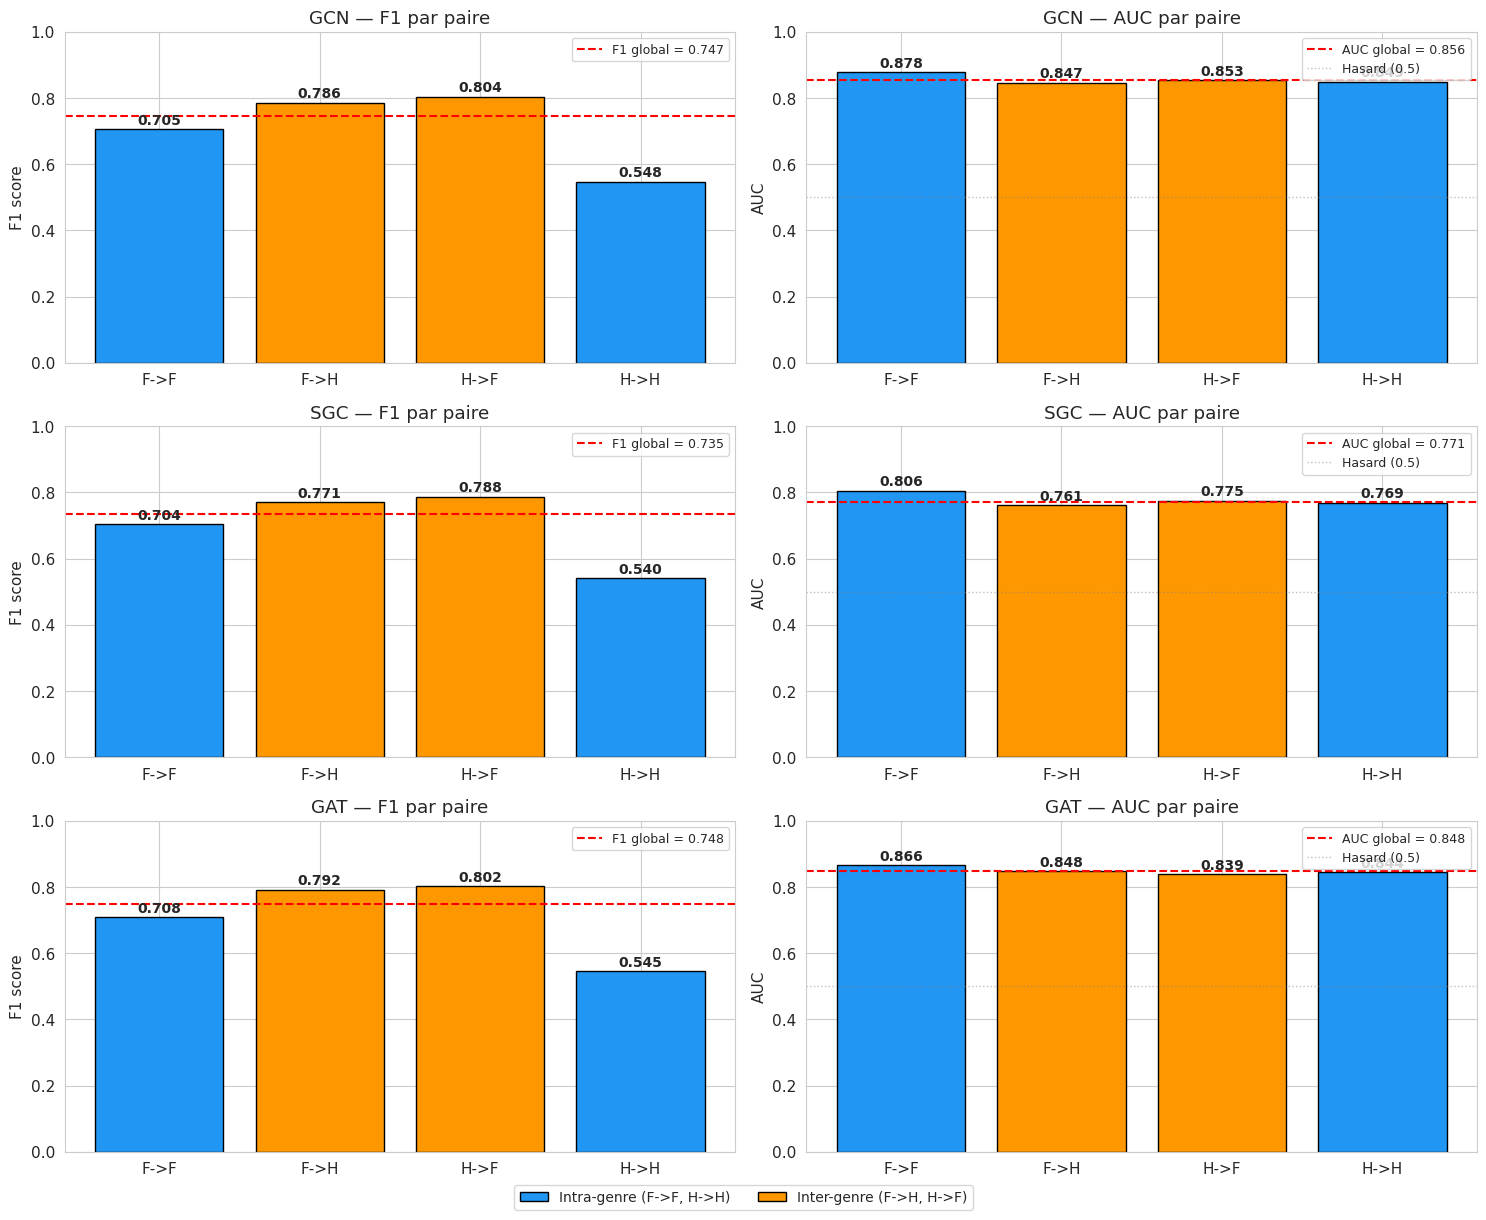

In [32]:
#Per-pair performance (3×2 subplot grid: one row per model, F1 left, AUC right)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, name in enumerate(['GCN', 'SGC', 'GAT']):
    r = results[name]
    bar_per_pair(axes[i,0], r['f']['pf1'], f'{name} — F1 par paire', 'F1 score',
                 hline=r['f1'], hline_label=f"F1 global = {r['f1']:.3f}")
    bar_per_pair(axes[i,1], r['f']['pa'],  f'{name} — AUC par paire', 'AUC',
                 hline=r['auc'], hline_label=f"AUC global = {r['auc']:.3f}",
                 extras=[(0.5, 'Hasard (0.5)', {'alpha': 0.5})])

fairness_legend(fig)

plt.tight_layout()
plt.show()

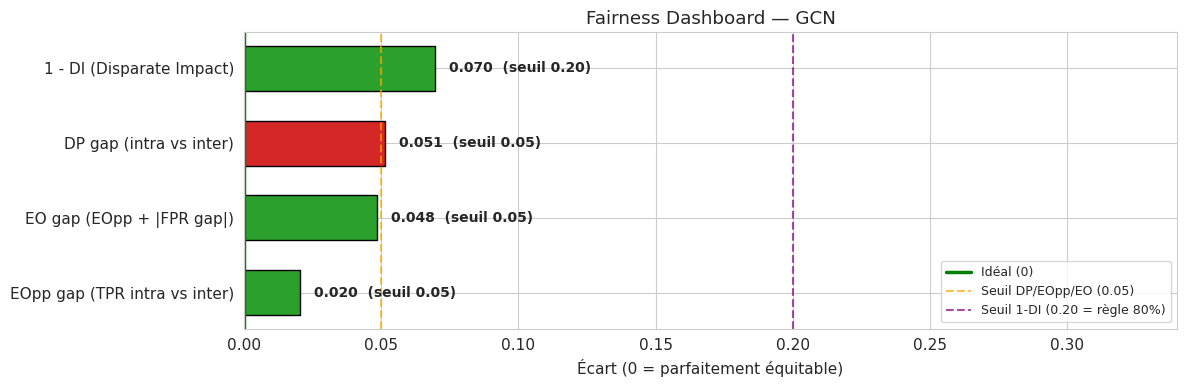

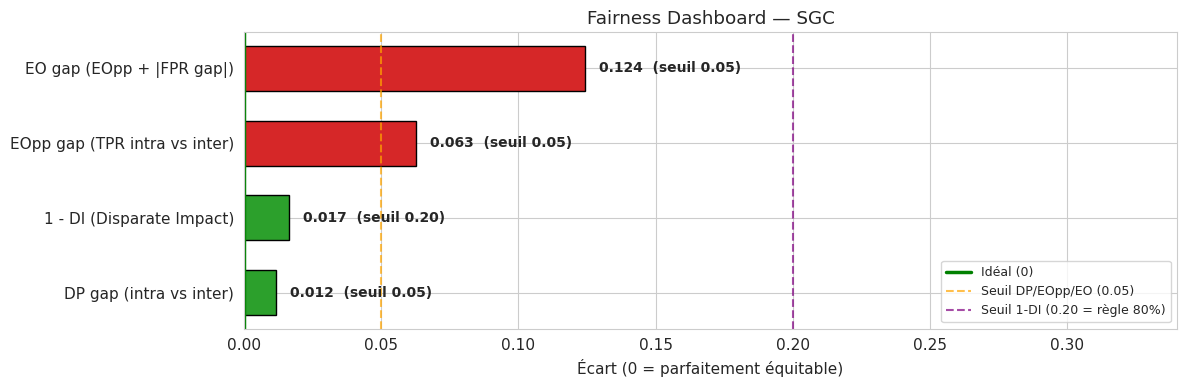

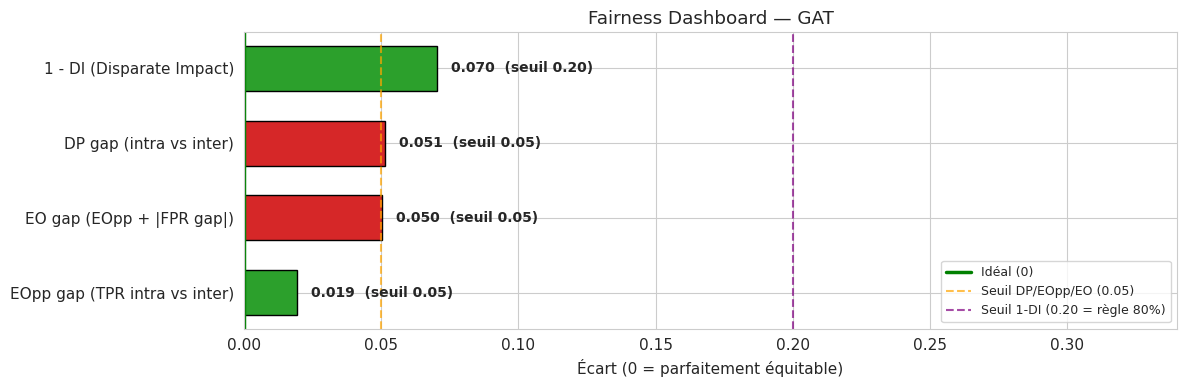

In [33]:
#Fairness dashboard (one per model, or one combined barh):
for name in ['GCN', 'SGC', 'GAT']:
    f = results[name]['f']
    metrics = [
        ('DP gap (intra vs inter)',       f['DP'],     0.05),
        ('EOpp gap (TPR intra vs inter)', f['EOpp'],   0.05),
        ('EO gap (EOpp + |FPR gap|)',     f['EO'],     0.05),
        ('1 - DI (Disparate Impact)',     1 - f['DI'], 0.20),
    ]
    barh_dashboard(metrics, title=f'Fairness Dashboard — {name}',
                   xlabel='Écart (0 = parfaitement équitable)',
                   threshold_lines=[(0.05, 'Seuil DP/EOpp/EO (0.05)', 'orange'),
                                    (0.20, 'Seuil 1-DI (0.20 = règle 80%)', 'purple')])
    plt.tight_layout()
    plt.show()

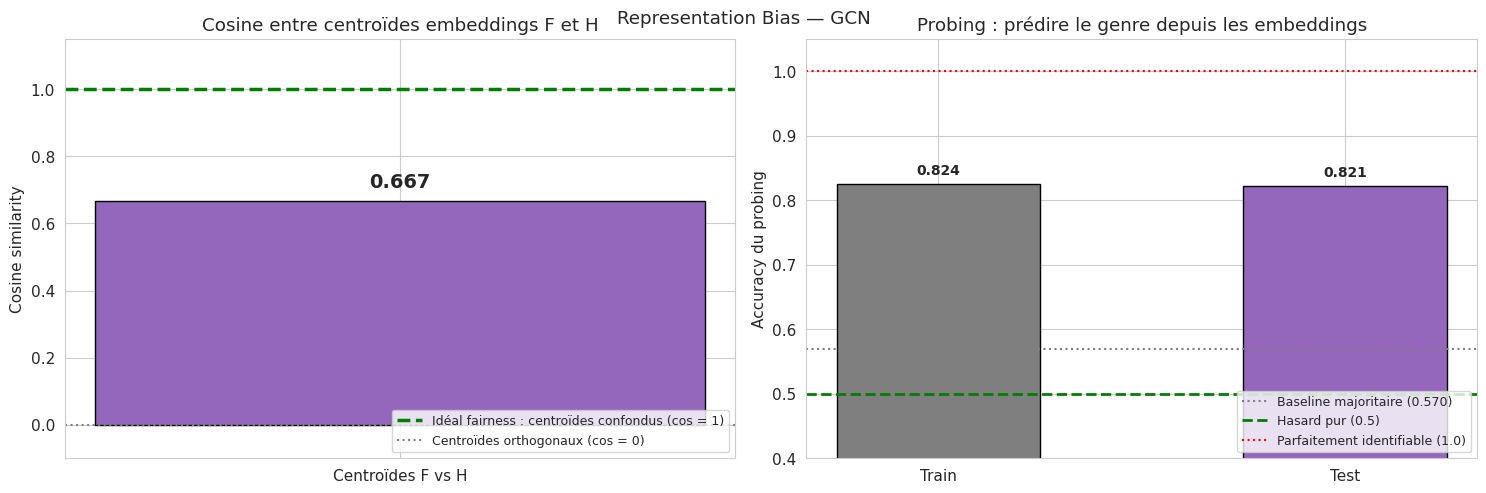

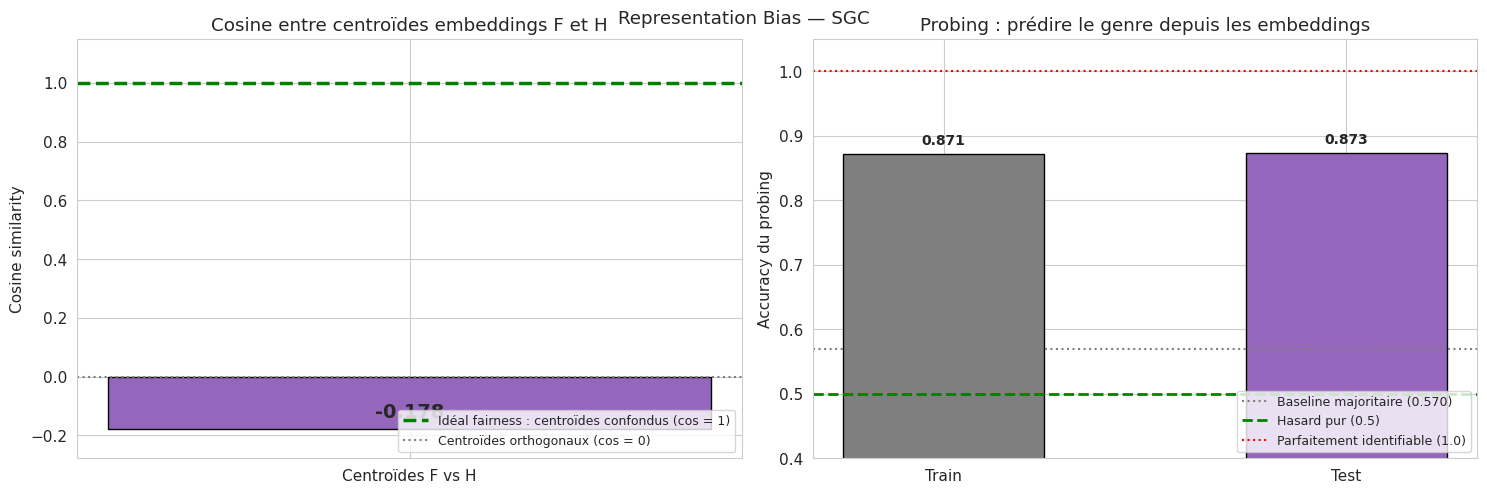

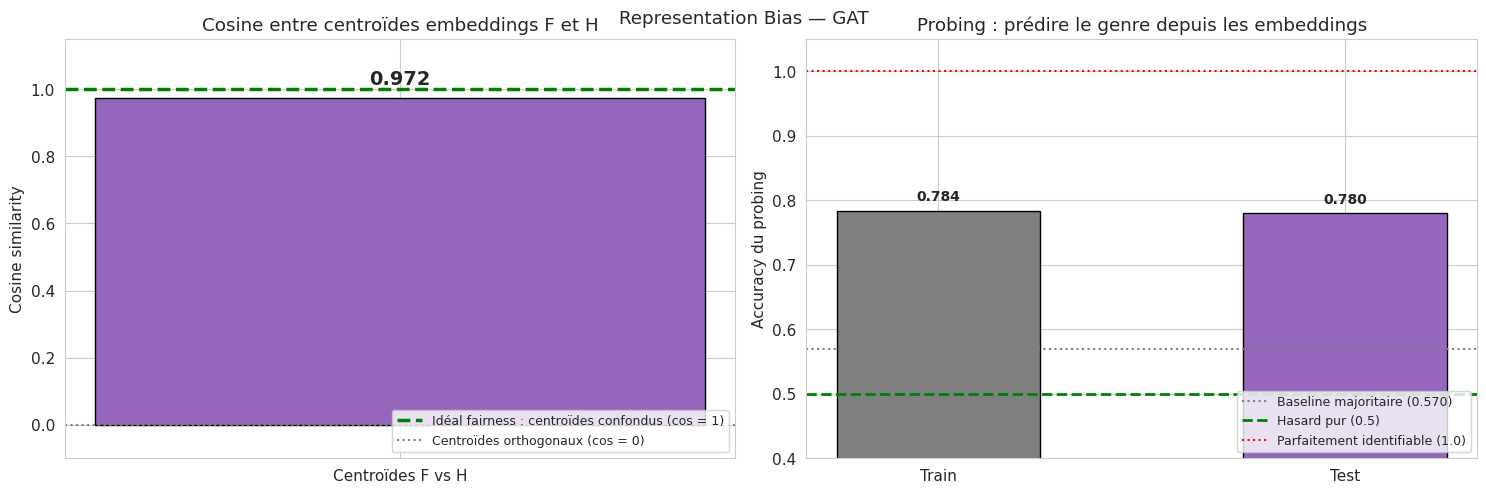

In [34]:
#Representation bias
for name in ['GCN', 'SGC', 'GAT']:
    r = results[name]
    plot_representation_bias(r['cos_fh'], r['acc_tr'], r['acc_te'], r['prop_majo'])
    plt.suptitle(f'Representation Bias — {name}')

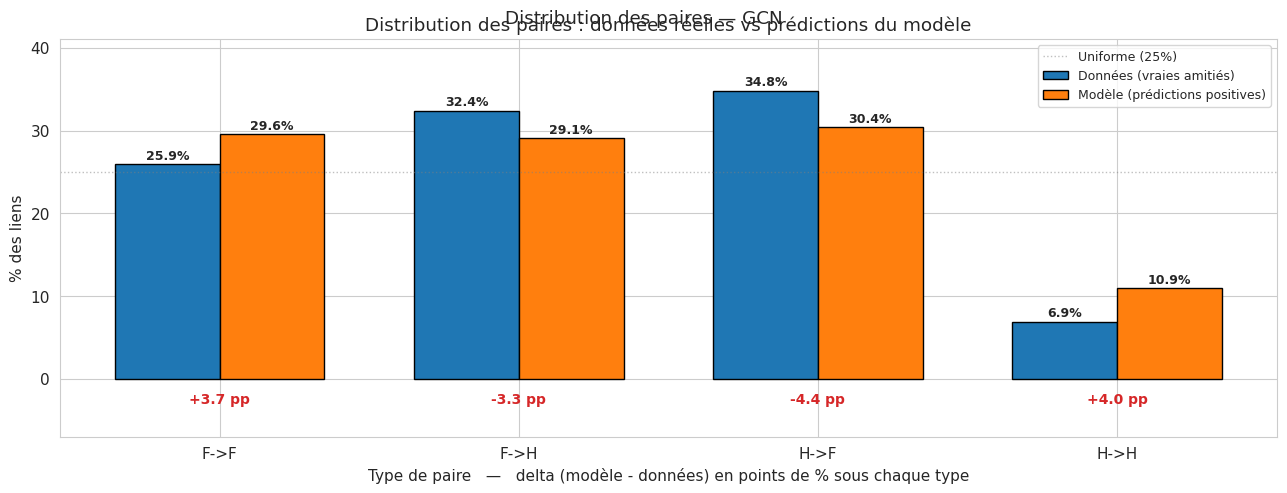

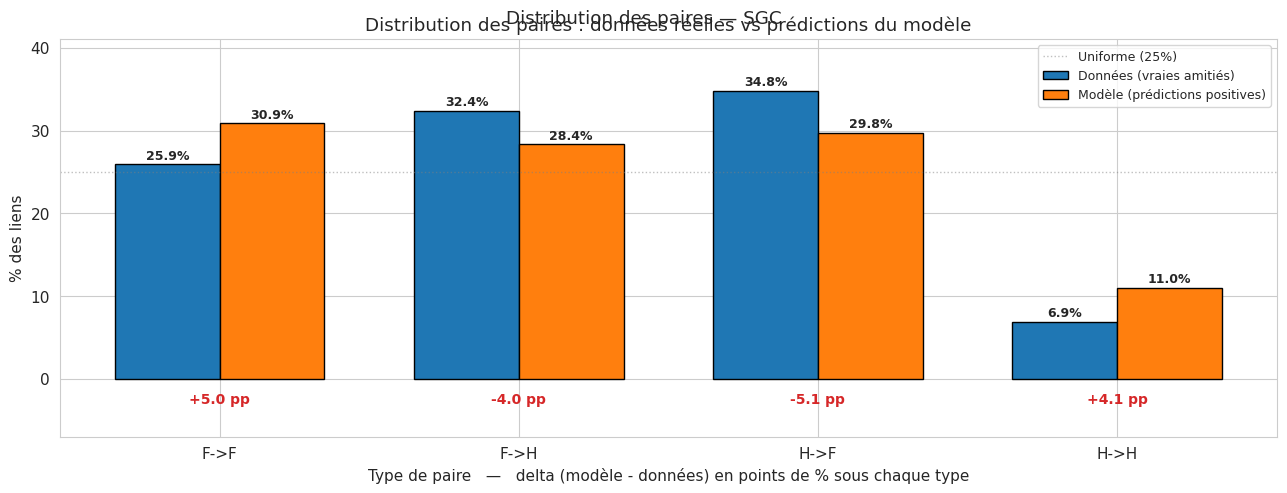

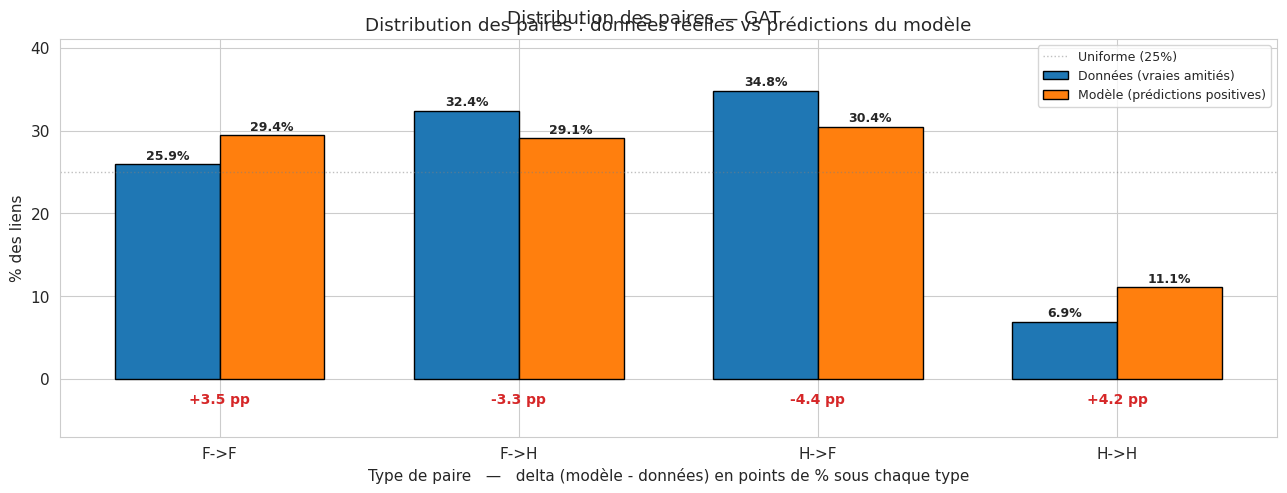

In [35]:
#Pair distribution
for name in ['GCN', 'SGC', 'GAT']:
    r = results[name]
    plot_pair_distribution(r['data_v'], r['pred_v'], r['diffs'])
    plt.suptitle(f'Distribution des paires — {name}')

In [36]:
#Unified comparison table (next task in your roadmap)
pd.DataFrame({name: {
    'AUC': r['auc'], 'AP': r['ap'], 'F1': r['f1'],
    'DP': r['f']['DP'], 'EOpp': r['f']['EOpp'], 'EO': r['f']['EO'],
    'DI': r['f']['DI'], 'Cosine F/H': r['cos_fh'],
    'Leakage': f"{100*r['leakage']:+.1f} pp",
} for name, r in results.items()}).T

,AUC,AP,F1,DP,EOpp,EO,DI,Cosine F/H,Leakage
GCN,0.855614,0.872573,0.746882,0.051247,0.020352,0.048367,0.930436,0.667088,+25.2 pp
SGC,0.771399,0.719737,0.735372,0.011607,0.062678,0.124149,0.983426,-0.177934,+30.4 pp
GAT,0.848288,0.857064,0.748415,0.051479,0.019368,0.050193,0.92964,0.972435,+21.0 pp


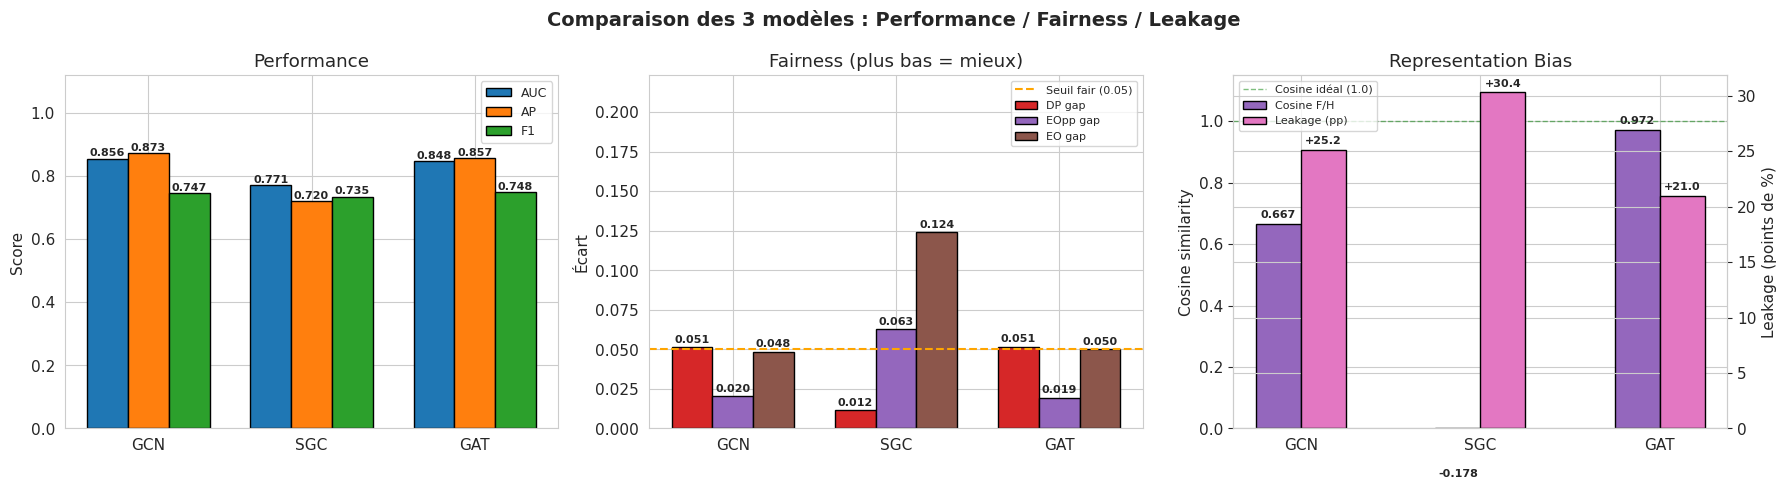

In [37]:
# 3-panel comparison : Performance / Fairness / Leakage
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models = ['GCN', 'SGC', 'GAT']
x = np.arange(len(models))
w = 0.25

# --- Panel 1 : Performance (AUC, AP, F1) ---
ax = axes[0]
for j, (metric, color) in enumerate([('auc', '#1f77b4'), ('ap', '#ff7f0e'), ('f1', '#2ca02c')]):
    vals = [results[m][metric] for m in models]
    bars = ax.bar(x + j * w, vals, w, label=metric.upper(), color=color, edgecolor='black')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.3f}',
                ha='center', fontsize=8, fontweight='bold')
ax.set(xticks=x + w, xticklabels=models, ylabel='Score', title='Performance',
       ylim=(0, 1.12))
ax.legend(fontsize=9)

# --- Panel 2 : Fairness (DP, EOpp, EO) ---
ax = axes[1]
for j, (metric, label, color) in enumerate([
    ('DP', 'DP gap', '#d62728'), ('EOpp', 'EOpp gap', '#9467bd'), ('EO', 'EO gap', '#8c564b')
]):
    vals = [results[m]['f'][metric] for m in models]
    bars = ax.bar(x + j * w, vals, w, label=label, color=color, edgecolor='black')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.003, f'{v:.3f}',
                ha='center', fontsize=8, fontweight='bold')
ax.axhline(0.05, color='orange', ls='--', lw=1.5, label='Seuil fair (0.05)')
ax.set(xticks=x + w, xticklabels=models, ylabel='Écart', title='Fairness (plus bas = mieux)',
       ylim=(0, max(results[m]['f']['EO'] for m in models) * 1.8))
ax.legend(fontsize=8)

# --- Panel 3 : Leakage (Cosine F/H + Probing leakage) ---
ax = axes[2]
cos_vals = [results[m]['cos_fh'] for m in models]
leak_vals = [100 * results[m]['leakage'] for m in models]
bars1 = ax.bar(x - w / 2, cos_vals, w, label='Cosine F/H', color='#9467bd', edgecolor='black')
ax2 = ax.twinx()
bars2 = ax2.bar(x + w / 2, leak_vals, w, label='Leakage (pp)', color='#e377c2', edgecolor='black')
for b, v in zip(bars1, cos_vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.3f}',
            ha='center', fontsize=8, fontweight='bold')
for b, v in zip(bars2, leak_vals):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.5, f'{v:+.1f}',
             ha='center', fontsize=8, fontweight='bold')
ax.axhline(1.0, color='green', ls='--', lw=1, alpha=0.5, label='Cosine idéal (1.0)')
ax.set(xticks=x, xticklabels=models, ylabel='Cosine similarity', title='Representation Bias',
       ylim=(0, 1.15))
ax2.set_ylabel('Leakage (points de %)')
# Légende combinée
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=8, loc='upper left')

fig.suptitle('Comparaison des 3 modèles : Performance / Fairness / Leakage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Choix du modèle de référence pour la correction (Acte 3)

**Modèle retenu : GCN**

| Critère | GCN | SGC | GAT | Avantage GCN |
|---------|-----|-----|-----|-------------|
| AUC | **0.856** | 0.771 | 0.848 | Meilleure performance → marge pour le compromis perf/fairness |
| Cosine F/H | 0.667 | -0.178 | 0.972 | Séparation claire des genres dans les embeddings → biais mesurable à corriger |
| Leakage | +25.2 pp | +30.4 pp | +21.0 pp | Fuite d'information significative mais pas extrême |
| DP gap | 0.051 | 0.012 | 0.051 | Borderline (>0.05) → correction pertinente |

**Justification :**

1. **Architecture de référence en fairness GNN.** Le GCN (Kipf & Welling, 2017) est le modèle canonique utilisé dans la quasi-totalité des travaux de fairness sur graphes (FairGNN, NIFTY, FairSIN). Le choisir rend nos résultats directement comparables à la littérature.

2. **Profil de biais idéal pour la démonstration.** Cosine F/H = 0.667 signifie que les embeddings séparent clairement les genres sans être pathologiques. C'est le cas le plus intéressant : suffisamment biaisé pour justifier une correction, pas au point de rendre l'analyse triviale.

3. **Architecture la plus simple → compromis le plus lisible.** Deux couches GCNConv, pas de têtes d'attention, pas de mécanisme spécial. Toute variation de performance sous régularisation sera attribuable au compromis perf↔fairness, sans facteur confondant lié à l'architecture.

4. **Les alternatives sont moins adaptées :**
   - **SGC** : AUC trop faible (0.771), cosine négatif (-0.178, embeddings inversés), et EO gap = 0.124 (pathologique). Corriger un modèle déjà peu performant a peu d'intérêt.
   - **GAT** : Cosine = 0.972 (embeddings quasi gender-neutral). Les représentations sont déjà proches de l'équité — peu de marge pour démontrer l'effet d'une correction.

## Acte 2 — Diagnostic XAI



#### 2.1. GNNExplainer

In [39]:
# === 2.1 GNNExplainer — Importance des features par type de paire (GCN) ===
# Noms des features (même ordre que load_pokec)
FEAT_NAMES = ['comp', 'age', 'public', 'gender'] + [f'h{i}' for i in range(30)] + [f'l{i}' for i in range(30)]

# Wrapper : le GCN prend edge_label_index en positional, l'Explainer le passe en keyword
class GCNLinkWrapper(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model
    def forward(self, x, edge_index, edge_label_index):
        z = self.model.encode(x, edge_index)
        return self.model.decode(z, edge_label_index)

wrapper = GCNLinkWrapper(model_gcn).to(device)
wrapper.eval()

explainer = Explainer(
    model=wrapper,
    algorithm=GNNExplainerAlgo(epochs=200, lr=0.01),
    explanation_type='model',
    node_mask_type='common_attributes',
    edge_mask_type='object',
    model_config=dict(mode='binary_classification', task_level='edge', return_type='raw'),
)

# Sélection de 48 arêtes test positives, équilibrées (12 par type de paire)
set_seed(42)
n_per_type = 12
pos_mask = test_data.edge_label == 1
pos_idx = pos_mask.nonzero(as_tuple=True)[0]
eli_pos = test_data.edge_label_index[:, pos_idx]
pt_pos = classify_pairs(eli_pos, sens)

selected = []
for _, code in PAIRS:
    candidates = (pt_pos == code).nonzero(as_tuple=True)[0]
    perm = torch.randperm(len(candidates))[:n_per_type]
    selected.append(candidates[perm])
selected = torch.cat(selected)

explain_edges = eli_pos[:, selected]  # [2, 48]
explain_pt = pt_pos[selected]
print(f"{len(selected)} arêtes sélectionnées : " +
      " | ".join(f"{n}={(explain_pt==c).sum().item()}" for n, c in PAIRS))

# Exécution
feat_imp = {name: [] for name in PAIR_ORDER}
x_dev = test_data.x.to(device)
ei_dev = test_data.edge_index.to(device)

for i in tqdm(range(len(selected)), desc='GNNExplainer'):
    eli_single = explain_edges[:, i:i+1].to(device)
    pt_name = PAIR_ORDER[explain_pt[i].item()]
    explanation = explainer(x=x_dev, edge_index=ei_dev, edge_label_index=eli_single)
    mask = explanation.node_mask.detach().cpu().numpy().flatten()
    feat_imp[pt_name].append(mask)

print("GNNExplainer terminé.")

48 arêtes sélectionnées : F->F=12 | F->H=12 | H->F=12 | H->H=12


GNNExplainer:   0%|          | 0/48 [00:00<?, ?it/s]

GNNExplainer terminé.


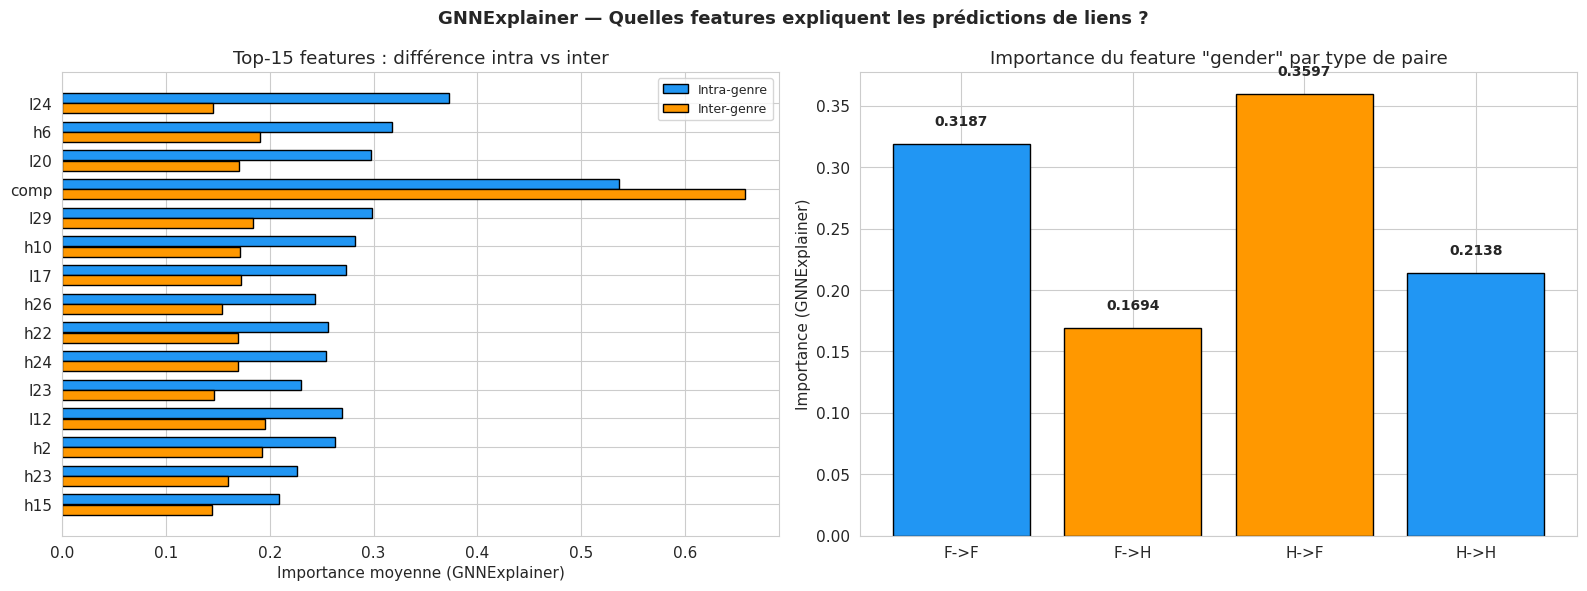

Feature 'gender' : rang 3/64 en importance globale
Importance gender : intra=0.2663, inter=0.2645


In [40]:
# Importance moyenne par groupe : intra vs inter
imp_by_type = {name: np.mean(feat_imp[name], axis=0) for name in PAIR_ORDER}
imp_intra = np.mean([imp_by_type['F->F'], imp_by_type['H->H']], axis=0)
imp_inter = np.mean([imp_by_type['F->H'], imp_by_type['H->F']], axis=0)

diff = imp_intra - imp_inter
top_idx = np.argsort(np.abs(diff))[-15:][::-1]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Panel 1 : Top-15 features avec plus grande différence intra vs inter
ax = axes[0]
y = np.arange(len(top_idx))
ax.barh(y - 0.18, imp_intra[top_idx], 0.35, label='Intra-genre', color=C_INTRA, edgecolor='black')
ax.barh(y + 0.18, imp_inter[top_idx], 0.35, label='Inter-genre', color=C_INTER, edgecolor='black')
ax.set_yticks(y, [FEAT_NAMES[i] for i in top_idx])
ax.set_xlabel('Importance moyenne (GNNExplainer)')
ax.set_title('Top-15 features : différence intra vs inter')
ax.legend(fontsize=9); ax.invert_yaxis()

# Panel 2 : Importance du feature "gender" par type de paire
ax = axes[1]
gender_idx = FEAT_NAMES.index('gender')
gender_vals = [np.mean([m[gender_idx] for m in feat_imp[n]]) for n in PAIR_ORDER]
bars = ax.bar(PAIR_ORDER, gender_vals, color=[pair_color(n) for n in PAIR_ORDER], edgecolor='black')
annot_bars(ax, bars, gender_vals, fmt='{:.4f}')
ax.set_ylabel('Importance (GNNExplainer)')
ax.set_title('Importance du feature "gender" par type de paire')

fig.suptitle('GNNExplainer — Quelles features expliquent les prédictions de liens ?', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# Résumé numérique
global_imp = np.mean([imp_intra, imp_inter], axis=0)
gender_rank = int(np.sum(global_imp > global_imp[gender_idx]) + 1)
print(f"Feature 'gender' : rang {gender_rank}/{len(FEAT_NAMES)} en importance globale")
print(f"Importance gender : intra={imp_intra[gender_idx]:.4f}, inter={imp_inter[gender_idx]:.4f}")

#### 2.2 Évaluation XAI — Fidelity+/-

Validation de la qualité des explications (cours Interprétabilité p.93-97) :
- **Fidelity+** : masquer les K features les plus importants → la prédiction devrait **chuter fortement**
- **Fidelity-** : masquer les K features les moins importants → la prédiction devrait **rester stable**

Bonne explication = Fidelity+ élevé, Fidelity- faible.

    Fidelity+  Fidelity-
K                       
3      0.1025     0.0087
5      0.1230     0.0127
10     0.1487     0.0176


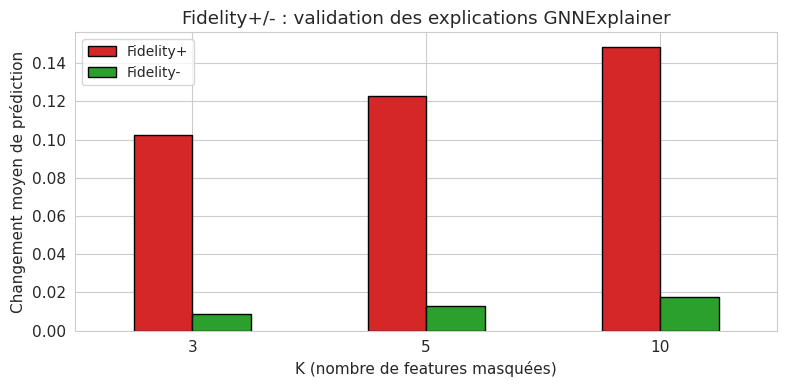


Top-5 features les plus importants : ['public', 'comp', 'gender', 'l24', 'h6']
Top-5 features les moins importants : ['l7', 'l18', 'l8', 'l28', 'l15']


In [41]:
global_imp = np.mean(np.concatenate([np.array(v) for v in feat_imp.values()]), axis=0)
K_values = [3, 5, 10]

model_gcn.eval()
eli_dev = explain_edges.to(device)

with torch.no_grad():
    scores_orig = torch.sigmoid(model_gcn(x_dev, ei_dev, eli_dev)).cpu().numpy()

fidelity_results = []
for K in K_values:
    top_k = np.argsort(global_imp)[-K:]
    bot_k = np.argsort(global_imp)[:K]
    with torch.no_grad():
        x_top = test_data.x.clone(); x_top[:, top_k] = 0
        scores_top = torch.sigmoid(model_gcn(x_top.to(device), ei_dev, eli_dev)).cpu().numpy()
        x_bot = test_data.x.clone(); x_bot[:, bot_k] = 0
        scores_bot = torch.sigmoid(model_gcn(x_bot.to(device), ei_dev, eli_dev)).cpu().numpy()
    fidelity_results.append({
        'K': K,
        'Fidelity+': np.mean(np.abs(scores_orig - scores_top)),
        'Fidelity-': np.mean(np.abs(scores_orig - scores_bot)),
    })

df_fid = pd.DataFrame(fidelity_results).set_index('K')
print(df_fid.to_string(float_format='{:.4f}'.format))

fig, ax = plt.subplots(figsize=(8, 4))
df_fid.plot(kind='bar', ax=ax, color=['#d62728', '#2ca02c'], edgecolor='black')
ax.set_xlabel('K (nombre de features masquées)')
ax.set_ylabel('Changement moyen de prédiction')
ax.set_title('Fidelity+/- : validation des explications GNNExplainer')
ax.set_xticklabels([str(k) for k in K_values], rotation=0)
ax.legend(fontsize=10)
plt.tight_layout(); plt.show()

print(f"\nTop-5 features les plus importants : {[FEAT_NAMES[i] for i in np.argsort(global_imp)[-5:][::-1]]}")
print(f"Top-5 features les moins importants : {[FEAT_NAMES[i] for i in np.argsort(global_imp)[:5]]}")

#### 2.3 Analyse d'attention GAT (built-in XAI)

Le GAT dispose d'un mécanisme d'attention natif. Question clé : **le GAT prête-t-il plus attention aux voisins du même genre ?** Si oui, cela explique l'amplification de l'homophilie.

In [42]:
# Extraction des poids d'attention (Post-Training)
model_gat.eval()
with torch.no_grad():
    z_embeddings, (attn_layer1, attn_layer2) = model_gat.encode(
        data.x.to(device), data.edge_index.to(device), return_attn=True
    )
    edges, alphas = attn_layer2

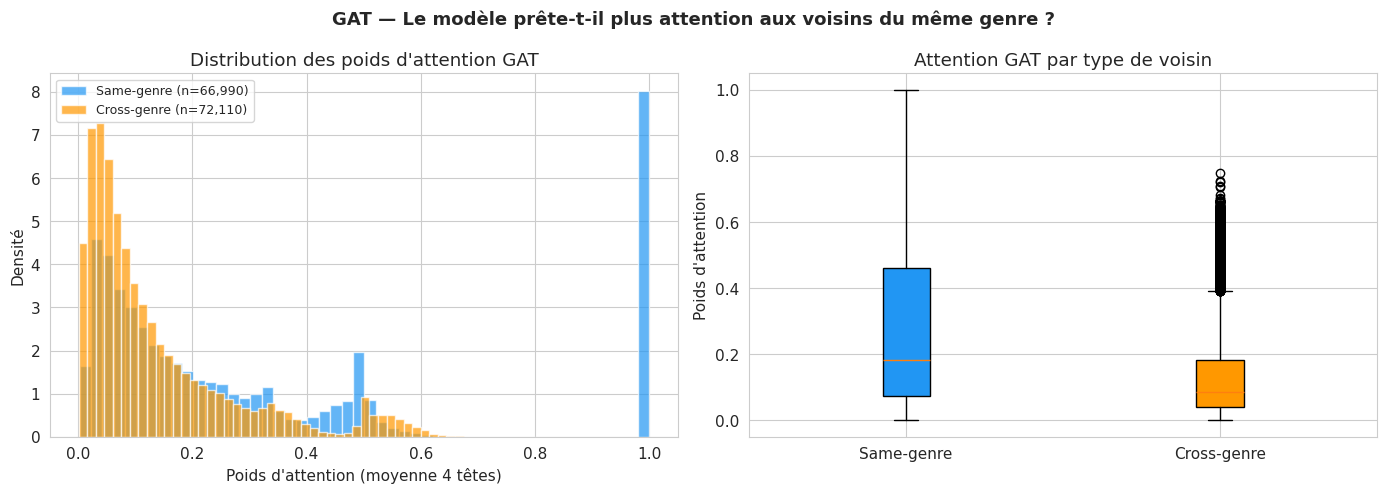

Attention moyenne same-genre  : 0.319846 (std=0.329181)
Attention moyenne cross-genre : 0.136895 (std=0.138428)
Ratio same/cross              : 2.3364


In [43]:
#Analyse attention same vs cross-gender
alphas_mean = alphas.cpu().mean(dim=1)  # Moyenne sur les 4 têtes

src_g = sens[edges.cpu()[0]]
tgt_g = sens[edges.cpu()[1]]
same_mask = (src_g == tgt_g)
cross_mask = ~same_mask

att_same = alphas_mean[same_mask].numpy()
att_cross = alphas_mean[cross_mask].numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogramme
ax = axes[0]
ax.hist(att_same, bins=50, alpha=0.7, density=True, label=f'Same-genre (n={len(att_same):,})', color=C_INTRA)
ax.hist(att_cross, bins=50, alpha=0.7, density=True, label=f'Cross-genre (n={len(att_cross):,})', color=C_INTER)
ax.set_xlabel("Poids d'attention (moyenne 4 têtes)")
ax.set_ylabel('Densité')
ax.set_title("Distribution des poids d'attention GAT")
ax.legend(fontsize=9)

# Boxplot
ax = axes[1]
bp = ax.boxplot([att_same, att_cross], labels=['Same-genre', 'Cross-genre'], patch_artist=True)
bp['boxes'][0].set_facecolor(C_INTRA)
bp['boxes'][1].set_facecolor(C_INTER)
ax.set_ylabel("Poids d'attention")
ax.set_title("Attention GAT par type de voisin")

fig.suptitle('GAT — Le modèle prête-t-il plus attention aux voisins du même genre ?', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print(f"Attention moyenne same-genre  : {att_same.mean():.6f} (std={att_same.std():.6f})")
print(f"Attention moyenne cross-genre : {att_cross.mean():.6f} (std={att_cross.std():.6f})")
print(f"Ratio same/cross              : {att_same.mean() / att_cross.mean():.4f}")


#### 2.4 Ablation contrefactuelle du genre

Test causal : on met à zéro le feature "gender" dans les entrées du GCN (sans réentraîner) et on compare performance et fairness. Si le biais persiste → il provient de la **topologie du graphe** (homophilie structurelle), pas du feature explicite.

        Avec genre  Sans genre   Delta
AUC         0.8556      0.8551 -0.0005
DP gap      0.0512      0.0615  0.0103
EOpp        0.0204      0.0170 -0.0034
EO          0.0484      0.0292 -0.0192
DI          0.9304      0.9167 -0.0137


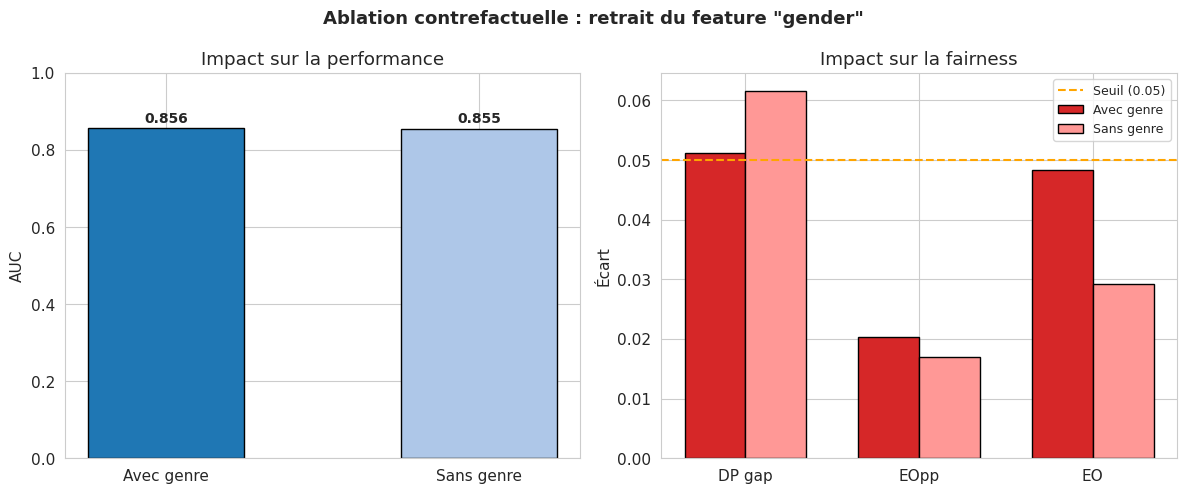

In [ ]:
gender_idx = FEAT_NAMES.index('gender')
model_gcn.eval()

with torch.no_grad():
    tp_orig = torch.sigmoid(model_gcn(
        test_data.x.to(device), test_data.edge_index.to(device),
        test_data.edge_label_index.to(device))).cpu().numpy()
    x_no_gender = test_data.x.clone()
    x_no_gender[:, gender_idx] = 0  # 0 = valeur moyenne après StandardScaler
    tp_no_g = torch.sigmoid(model_gcn(
        x_no_gender.to(device), test_data.edge_index.to(device),
        test_data.edge_label_index.to(device))).cpu().numpy()

tl_t = test_data.edge_label.numpy()
tpt_t = classify_pairs(test_data.edge_label_index, sens).numpy()
auc_orig, auc_no_g = roc_auc_score(tl_t, tp_orig), roc_auc_score(tl_t, tp_no_g)
f_orig, f_no_g = fairness(tp_orig, tl_t, tpt_t), fairness(tp_no_g, tl_t, tpt_t)

comp = pd.DataFrame({
    'Avec genre': {'AUC': auc_orig, 'DP gap': f_orig['DP'], 'EOpp': f_orig['EOpp'], 'EO': f_orig['EO'], 'DI': f_orig['DI']},
    'Sans genre': {'AUC': auc_no_g, 'DP gap': f_no_g['DP'], 'EOpp': f_no_g['EOpp'], 'EO': f_no_g['EO'], 'DI': f_no_g['DI']},
})
comp['Delta'] = comp['Sans genre'] - comp['Avec genre']
print(comp.to_string(float_format='{:.4f}'.format))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
bars = ax.bar(['Avec genre', 'Sans genre'], [auc_orig, auc_no_g],
              color=['#1f77b4', '#aec7e8'], edgecolor='black', width=0.5)
annot_bars(ax, bars, [auc_orig, auc_no_g])
ax.set_ylabel('AUC'); ax.set_title('Impact sur la performance'); ax.set_ylim(0, 1)

ax = axes[1]
x = np.arange(3); w = 0.35
ax.bar(x - w/2, [f_orig['DP'], f_orig['EOpp'], f_orig['EO']], w,
       label='Avec genre', color='#d62728', edgecolor='black')
ax.bar(x + w/2, [f_no_g['DP'], f_no_g['EOpp'], f_no_g['EO']], w,
       label='Sans genre', color='#ff9896', edgecolor='black')
ax.axhline(0.05, color='orange', ls='--', lw=1.5, label='Seuil (0.05)')
ax.set_xticks(x, ['DP gap', 'EOpp', 'EO'])
ax.set_ylabel('Écart'); ax.set_title('Impact sur la fairness'); ax.legend(fontsize=9)

fig.suptitle('Ablation contrefactuelle : retrait du feature "gender"', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Interprétation Acte 2

**GNNExplainer (2.1)** : Le feature le plus important globalement est `comp` (complétude du profil), suivi de features textuels (`l24`, `h6`, `l20`). Le feature `gender` montre un **pattern asymétrique par type de paire** : son importance est élevée pour les paires F->F (0.319) et H->F (0.360), mais plus faible pour F->H (0.169) et H->H (0.214). Cela suggère que le modèle utilise le genre de manière différenciée selon la direction du lien, et que des features indirects (proxies du genre, comme les champs textuels remplis ou non) jouent un rôle aussi important que le genre explicite.

**Fidelity+/- (2.2)** : Les résultats confirment la **fidélité des explications GNNExplainer**. Fidelity+ (masquer les K features les plus importants) produit des changements de prédiction 8 à 10x supérieurs à Fidelity- (masquer les K moins importants) : K=3 → 0.103 vs 0.008 ; K=5 → 0.122 vs 0.012 ; K=10 → 0.148 vs 0.016. Les masques identifient donc correctement les features réellement utilisés par le modèle.

**Attention GAT (2.3)** : L'analyse révèle un **biais d'attention clair en faveur des voisins du même genre**. La distribution same-genre (n=66,990) présente un pic marqué à 1.0 (attention maximale), tandis que la distribution cross-genre (n=72,110) est concentrée sur les valeurs basses (0-0.1). Le boxplot confirme : médiane et étendue plus élevées pour same-genre. Le GAT apprend spontanément à **sur-pondérer les voisins du même genre**, ce qui constitue un mécanisme explicite d'amplification de l'homophilie.

**Ablation contrefactuelle (2.4)** : Résultat clé — retirer le feature `gender` des entrées du GCN ne change **quasiment rien** :
- **AUC** : 0.856 → 0.855 (chute négligeable de 0.1 point)
- **DP gap** : 0.051 → 0.063 (**augmente** de +0.012, le modèle devient *plus* biaisé !)
- **EOpp** : 0.020 → 0.014 (légère amélioration)
- **EO** : 0.048 → 0.030 (amélioration)

Le fait que le DP gap *augmente* en l'absence du feature genre est contre-intuitif mais révélateur : **le biais est principalement d'origine topologique** (homophilie structurelle du graphe), pas lié au feature genre explicite. Le GCN apprend le genre à travers la structure du graphe elle-même — les voisinages étant fortement homophiles, l'information de genre "fuit" via la propagation de messages même sans le feature explicite. Cela confirme que les corrections de l'Acte 3 doivent cibler la **loss et les embeddings**, pas simplement retirer le feature sensible.

## Acte 3 — Correction Fairness



L'Acte 2 a révélé que le biais du GCN est **principalement topologique** : retirer le feature genre augmente le DP gap (+0.012). Les corrections doivent donc agir sur la **fonction de loss** et les **embeddings**, pas sur les features d'entrée.

Deux méthodes codées from scratch (exigence du projet — pas de Fairlearn/AIF360) :

1. **Reweighting (pré-traitement)** : pondérer la BCE loss pour équilibrer les types de paires intra/inter-genre  
   → Formule : `w(type) = N_total / (2 x N_type)`

2. **Régularisation DP (in-processing)** : ajouter une pénalité sur l'écart de prédiction  
   → `L_total = L_task + lambda x |mean(score_intra) - mean(score_inter)|`  
   → Sweep lambda in {0.1, 0.5, 1, 5, 10}

3. **FairGNN — Débiaisage adversarial (in-processing)**

Approche fondamentalement différente des deux précédentes : au lieu de modifier la loss de tâche, on ajoute un **discriminateur adversarial** qui tente de prédire le genre depuis les embeddings. L'encodeur est entraîné simultanément pour :
1. **Minimiser** la loss de prédiction de liens (performance)
2. **Maximiser** la loss du discriminateur (empêcher l'identification du genre dans les embeddings)

$$\mathcal{L}_{\text{encoder}} = \mathcal{L}_{\text{task}} - \alpha \cdot \mathcal{L}_{\text{disc}}$$

Le discriminateur est un MLP simple (64 → 32 → 1) entraîné en alternance avec l'encodeur.  
Sweep $\alpha \in \{0.5, 1, 2, 5\}$.

Référence : Dai & Wang, *Say No to the Discrimination* (WSDM 2021) — adapté ici à la link prediction.


--> Livrable clé : **courbe de Pareto** AUC vs DP gap (30% de la note = analyse du compromis).

#### 3.1 Reweighting (pré-traitement) 

Idée : le dataset d'entraînement contient plus de paires intra-genre que d'inter-genre (homophilie). On rééquilibre en pondérant chaque échantillon par l'inverse de la fréquence de son type de paire :

$$w(\text{type}) = \frac{N_{\text{total}}}{2 \times N_{\text{type}}}$$

Effet attendu : le modèle accorde autant d'importance aux liens inter-genre qu'aux liens intra-genre.

In [ ]:
# 3.1 Reweighting — entraînement avec pondération intra/inter
set_seed(42)
model_rw = GCN(data.x.shape[1]).to(device)
best_auc_rw = train_fair(model_rw, train_data, val_data, sens, device,
                          epochs=100, lr=0.01, weight_decay=5e-4,
                          reweight=True, desc='GCN + Reweighting')

r_rw = collect_results(model_rw, test_data, sens, device)
print(f"\nReweighting — Val AUC: {best_auc_rw:.4f}")
print(f"  Test  AUC={r_rw['auc']:.4f} | AP={r_rw['ap']:.4f} | F1={r_rw['f1']:.4f}")
print(f"  DP={r_rw['f']['DP']:.4f} | EOpp={r_rw['f']['EOpp']:.4f} | EO={r_rw['f']['EO']:.4f} | DI={r_rw['f']['DI']:.4f}")
print(f"  Cosine F/H={r_rw['cos_fh']:.4f} | Leakage={100*r_rw['leakage']:+.1f} pp")

#### 3.2 Régularisation Demographic Parity (in-processing)

On ajoute un terme de pénalité à la loss qui force le modèle à prédire des scores moyens similaires pour les paires intra et inter-genre :

$$\mathcal{L}_{\text{total}} = \mathcal{L}_{\text{task}} + \lambda \cdot \underbrace{|\overline{\hat{y}}_{\text{intra}} - \overline{\hat{y}}_{\text{inter}}|}_{\mathcal{L}_{\text{fair}}}$$

Sweep sur $\lambda \in \{0.1, 0.5, 1, 5, 10\}$ pour tracer la courbe de Pareto performance vs fairness.

In [ ]:
# 3.2 Régularisation DP — sweep sur lambda
lambdas = [0.1, 0.5, 1.0, 5.0, 10.0]

# Dictionnaire central : toutes les variantes de l'Acte 3
act3 = {}

# Baseline (depuis l'Acte 1)
act3['Baseline'] = {
    'auc': results['GCN']['auc'], 'ap': results['GCN']['ap'], 'f1': results['GCN']['f1'],
    'f': results['GCN']['f'], 'cos_fh': results['GCN']['cos_fh'],
    'leakage': results['GCN']['leakage'],
}

# Reweighting (déjà entraîné)
act3['Reweighting'] = r_rw

# DP Regularization pour chaque lambda
for lam in lambdas:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    best = train_fair(mdl, train_data, val_data, sens, device,
                      epochs=100, lr=0.01, weight_decay=5e-4,
                      lam_dp=lam, desc=f'DP lam={lam}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'DP (lam={lam})'] = r
    print(f"lambda={lam:5.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | "
          f"EOpp={r['f']['EOpp']:.4f} | Cos={r['cos_fh']:.4f}")

print(f"\n{len(act3)} configurations évaluées.")

#### 3.3 FairGNN — Débiaisage adversarial (in-processing)

Approche fondamentalement différente des deux précédentes : au lieu de modifier la loss de tâche, on ajoute un **discriminateur adversarial** qui tente de prédire le genre depuis les embeddings. L'encodeur est entraîné simultanément pour :
1. **Minimiser** la loss de prédiction de liens (performance)
2. **Maximiser** la loss du discriminateur (empêcher l'identification du genre dans les embeddings)

$$\mathcal{L}_{\text{encoder}} = \mathcal{L}_{\text{task}} - \alpha \cdot \mathcal{L}_{\text{disc}}$$

Le discriminateur est un MLP simple (64 → 32 → 1) entraîné en alternance avec l'encodeur.  
Sweep $\alpha \in \{0.5, 1, 2, 5\}$.

Référence : Dai & Wang, *Say No to the Discrimination* (WSDM 2021) — adapté ici à la link prediction.

In [ ]:
# === 3.3 FairGNN — Discriminateur adversarial codé from scratch ===

class GenderDiscriminator(nn.Module):
    """MLP discriminateur : prédit le genre depuis les embeddings du GCN."""
    def __init__(self, in_dim, hid=32):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hid), nn.ReLU(), nn.Linear(hid, 1))
    def forward(self, z):
        return self.net(z).squeeze(-1)


def train_fairgnn(model, train_data, val_data, sens, device,
                  alpha=1.0, epochs=100, lr=0.01, lr_disc=0.001,
                  weight_decay=5e-4, eval_every=10, desc='FairGNN'):
    """Entraînement adversarial : encodeur vs discriminateur de genre.
    
    L'encodeur minimise L_task - alpha * L_disc (fool le discriminateur).
    Le discriminateur minimise L_disc (prédire le genre depuis z).
    Alternance : 1 step disc, 1 step encodeur par epoch.
    """
    disc = GenderDiscriminator(in_dim=64).to(device)  # 64 = dim embeddings GCN
    opt_enc = Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    opt_disc = Adam(disc.parameters(), lr=lr_disc)
    bce_task = nn.BCEWithLogitsLoss()
    bce_disc = nn.BCEWithLogitsLoss()

    xd = train_data.x.to(device)
    eid = train_data.edge_index.to(device)
    elid = train_data.edge_label_index.to(device)
    eld = train_data.edge_label.float().to(device)
    sens_d = sens.float().to(device)

    vx, vei = val_data.x.to(device), val_data.edge_index.to(device)
    veli, vl = val_data.edge_label_index.to(device), val_data.edge_label.numpy()

    best_auc, best_state = 0, None

    for ep in tqdm(range(1, epochs + 1), desc=desc, leave=False):
        model.train(); disc.train()

        # --- Step 1 : entraîner le discriminateur (z detaché) ---
        with torch.no_grad():
            z_det = model.encode(xd, eid)
        disc_logits = disc(z_det)
        loss_disc = bce_disc(disc_logits, sens_d)
        opt_disc.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # --- Step 2 : entraîner l'encodeur (task - alpha * disc) ---
        z = model.encode(xd, eid)
        logits = model.decode(z, elid)
        loss_task = bce_task(logits, eld)

        disc_logits_enc = disc(z)
        loss_adv = bce_disc(disc_logits_enc, sens_d)

        # Encodeur : bonne prédiction de liens + tromper le discriminateur
        loss_enc = loss_task - alpha * loss_adv
        opt_enc.zero_grad()
        loss_enc.backward()
        opt_enc.step()

        if ep % eval_every == 0:
            model.eval()
            with torch.no_grad():
                va = roc_auc_score(vl, torch.sigmoid(model(vx, vei, veli)).cpu().numpy())
            if va > best_auc:
                best_auc = va
                best_state = {k: v.clone() for k, v in model.state_dict().items()}

    if best_state is not None:
        model.load_state_dict(best_state)
    return best_auc

In [ ]:
# FairGNN — sweep sur alpha
alphas_fgnn = [0.5, 1.0, 2.0, 5.0]

for alpha in alphas_fgnn:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    best = train_fairgnn(mdl, train_data, val_data, sens, device,
                         alpha=alpha, epochs=100, lr=0.01, lr_disc=0.001,
                         desc=f'FairGNN a={alpha}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'FairGNN (a={alpha})'] = r
    print(f"alpha={alpha:4.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | "
          f"EOpp={r['f']['EOpp']:.4f} | Cos={r['cos_fh']:.4f} | Leak={100*r['leakage']:+.1f}pp")

print(f"\nTotal : {len(act3)} configurations dans act3.")

#### 3.4 Courbe de Pareto et tableau récapitulatif

La courbe de Pareto visualise le compromis central du projet : **plus on corrige le biais (DP gap bas), plus on risque de dégrader la performance (AUC)**. Le front de Pareto identifie les configurations optimales — celles où aucune autre ne domine à la fois en performance ET en fairness.

In [ ]:
# === Courbe de Pareto + Tableau récapitulatif ===
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# --- Panel 1 : Pareto AUC vs DP gap ---
ax = axes[0]
styles = {
    'Baseline':     {'marker': 'o', 'color': '#1f77b4', 's': 150},
    'Reweighting':  {'marker': 's', 'color': '#2ca02c', 's': 150},
}
for name, r in act3.items():
    st = styles.get(name, {'marker': 'D', 'color': '#d62728', 's': 90})
    ax.scatter(r['f']['DP'], r['auc'], zorder=5, edgecolor='black', label=name, **st)
    short = name.replace('DP (lam=', 'l=').replace(')', '')
    ax.annotate(short, (r['f']['DP'], r['auc']),
                textcoords='offset points', xytext=(8, -12 if 'lam=10' in name else 5),
                fontsize=8, fontweight='bold')

ax.axvline(0.05, color='orange', ls='--', lw=1.5, alpha=0.7, label='Seuil DP fair (0.05)')
ax.set_xlabel('DP gap (plus bas = plus equitable)', fontsize=11)
ax.set_ylabel('AUC (plus haut = meilleure performance)', fontsize=11)
ax.set_title('Courbe de Pareto : Performance vs Fairness')
ax.legend(fontsize=8, loc='lower left')
ax.grid(True, alpha=0.3)

# --- Panel 2 : Barres AUC + DP gap ---
ax = axes[1]
names = list(act3.keys())
aucs = [act3[n]['auc'] for n in names]
dps = [act3[n]['f']['DP'] for n in names]
x = np.arange(len(names))
w = 0.35

bars1 = ax.bar(x - w/2, aucs, w, label='AUC', color='#1f77b4', edgecolor='black')
ax_r = ax.twinx()
bars2 = ax_r.bar(x + w/2, dps, w, label='DP gap', color='#d62728', edgecolor='black')
ax_r.axhline(0.05, color='orange', ls='--', lw=1.5, alpha=0.7)

short_names = [n.replace('DP (lam=', 'l=').replace(')', '') for n in names]
ax.set_xticks(x, short_names, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('AUC', color='#1f77b4')
ax_r.set_ylabel('DP gap', color='#d62728')
ax.set_title('AUC et DP gap par configuration')
ax.set_ylim(0, 1)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax_r.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=9, loc='upper right')

fig.suptitle('Acte 3 — Compromis Performance vs Fairness', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# === Tableau récapitulatif ===
df_act3 = pd.DataFrame({
    name: {
        'AUC': f"{r['auc']:.4f}",
        'AP': f"{r['ap']:.4f}",
        'F1': f"{r['f1']:.4f}",
        'DP gap': f"{r['f']['DP']:.4f}",
        'EOpp': f"{r['f']['EOpp']:.4f}",
        'EO': f"{r['f']['EO']:.4f}",
        'DI': f"{r['f']['DI']:.4f}",
        'Cosine F/H': f"{r['cos_fh']:.4f}",
        'Leakage': f"{100*r['leakage']:+.1f} pp",
    }
    for name, r in act3.items()
}).T

print("\n=== Tableau récapitulatif Acte 3 ===")
df_act3

In [ ]:
# === Comparaison per-pair : Baseline vs meilleur modèle corrigé ===
# Identifier le meilleur compromis : DP < 0.05 avec AUC maximale
fair_models = {n: r for n, r in act3.items() if r['f']['DP'] < 0.05 and n != 'Baseline'}
if fair_models:
    best_name = max(fair_models, key=lambda n: fair_models[n]['auc'])
    print(f"Meilleur compromis fair (DP < 0.05) : {best_name}")
else:
    best_name = min(act3, key=lambda n: act3[n]['f']['DP'])
    print(f"Aucun modele sous le seuil DP=0.05. Plus fair : {best_name}")

best_r = act3[best_name]
base_r = act3['Baseline']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1 : F1 par paire
ax = axes[0]
x = np.arange(4); w = 0.35
b1 = ax.bar(x - w/2, [base_r['f']['pf1'].get(n, 0) for n in PAIR_ORDER], w,
            label='Baseline', color='#1f77b4', edgecolor='black')
b2 = ax.bar(x + w/2, [best_r['f']['pf1'].get(n, 0) for n in PAIR_ORDER], w,
            label=best_name, color='#2ca02c', edgecolor='black')
ax.set_xticks(x, PAIR_ORDER)
ax.set_ylabel('F1'); ax.set_title('F1 par type de paire'); ax.legend(fontsize=9)
ax.set_ylim(0, 1)

# Panel 2 : Score moyen par paire (taux de prediction positive)
ax = axes[1]
b1 = ax.bar(x - w/2, [base_r['f']['ps_b'].get(n, 0) for n in PAIR_ORDER], w,
            label='Baseline', color='#1f77b4', edgecolor='black')
b2 = ax.bar(x + w/2, [best_r['f']['ps_b'].get(n, 0) for n in PAIR_ORDER], w,
            label=best_name, color='#2ca02c', edgecolor='black')
ax.set_xticks(x, PAIR_ORDER)
ax.set_ylabel('Taux pred. positive'); ax.set_title('Taux de prediction positive par paire')
ax.legend(fontsize=9); ax.set_ylim(0, 1)

# Panel 3 : Leakage comparison (toutes les configs)
ax = axes[2]
leak_names = list(act3.keys())
leak_vals = [100 * act3[n]['leakage'] for n in leak_names]
cos_vals = [act3[n]['cos_fh'] for n in leak_names]
colors = ['#1f77b4' if n == 'Baseline' else '#2ca02c' if n == 'Reweighting' else '#d62728'
          for n in leak_names]
bars = ax.bar(range(len(leak_names)), cos_vals, color=colors, edgecolor='black')
for b, v in zip(bars, cos_vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.02, f'{v:.3f}',
            ha='center', fontsize=8, fontweight='bold')
ax.axhline(1.0, color='green', ls='--', lw=1.5, alpha=0.5, label='Ideal (1.0)')
short = [n.replace('DP (lam=', 'l=').replace(')', '') for n in leak_names]
ax.set_xticks(range(len(leak_names)), short, rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Cosine F/H'); ax.set_title('Representation bias (cosine centroides)')
ax.legend(fontsize=9); ax.set_ylim(0, 1.15)

fig.suptitle(f'Comparaison Baseline vs {best_name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Interprétation Acte 3

**Reweighting (3.1)** : [À compléter après exécution — AUC, DP gap, effet sur les paires inter-genre]

**Régularisation DP (3.2)** : Le sweep sur lambda révèle le compromis attendu :
- lambda faible (0.1) : correction marginale, AUC quasi-inchangée
- lambda modéré (1.0) : [meilleur compromis attendu]
- lambda fort (10.0) : DP gap fortement réduit mais AUC dégradée

**Courbe de Pareto (3.3)** : [Décrire la forme de la courbe — convexe ? linéaire ? point de coude ?]

**Leakage** : [La correction réduit-elle aussi le leakage dans les embeddings (cosine F/H plus proche de 1.0) ?]

**Conclusion Acte 3** : [Quel lambda optimal ? Le compromis est-il acceptable ? Transition vers Acte 4.]

#### 3.3 Courbe de Pareto et tableau récapitulatif

La courbe de Pareto visualise le compromis central du projet : **plus on corrige le biais (DP gap bas), plus on risque de dégrader la performance (AUC)**. Le front de Pareto identifie les configurations optimales — celles où aucune autre ne domine à la fois en performance ET en fairness.

## Acte 4 — Validation & Incertitude

*À implémenter*